# ДЗ 2. Наложение и удаление шума

**Цель:** добавить к изображению гауссов и постоянный шум, а затем сравнить несколько фильтров по метрикам MSE и SSIM.

Для основного опыта использовано изображение `sar_1.jpg`. Шумовые составляющие сделаны положительными, как указано в задании.

In [1]:
from pathlib import Path

import cv2
import numpy as np
import matplotlib.pyplot as plt
from skimage.metrics import mean_squared_error, structural_similarity

plt.rcParams['figure.dpi'] = 110
rng = np.random.default_rng(42)                                

def find_file(name):
    variants = [Path(name), Path('D:/DownLoads') / name]
    for path in variants:
        if path.exists():
            return path
    raise FileNotFoundError(f'Не найден файл {name}')

sar_path = find_file('sar_1.jpg')
flower_path = find_file('img.jpg')
print('Основное изображение:', sar_path)
print('Дополнительное изображение:', flower_path)

Основное изображение: D:\DownLoads\sar_1.jpg
Дополнительное изображение: D:\DownLoads\img.jpg


## 1. Исходные изображения

Цветное изображение с цветком добавлено в материалы. Оно будет использовано в конце для короткой дополнительной проверки.

Размер sar_1.jpg: (675, 1200)
Размер img.jpg: (4000, 6000, 3)


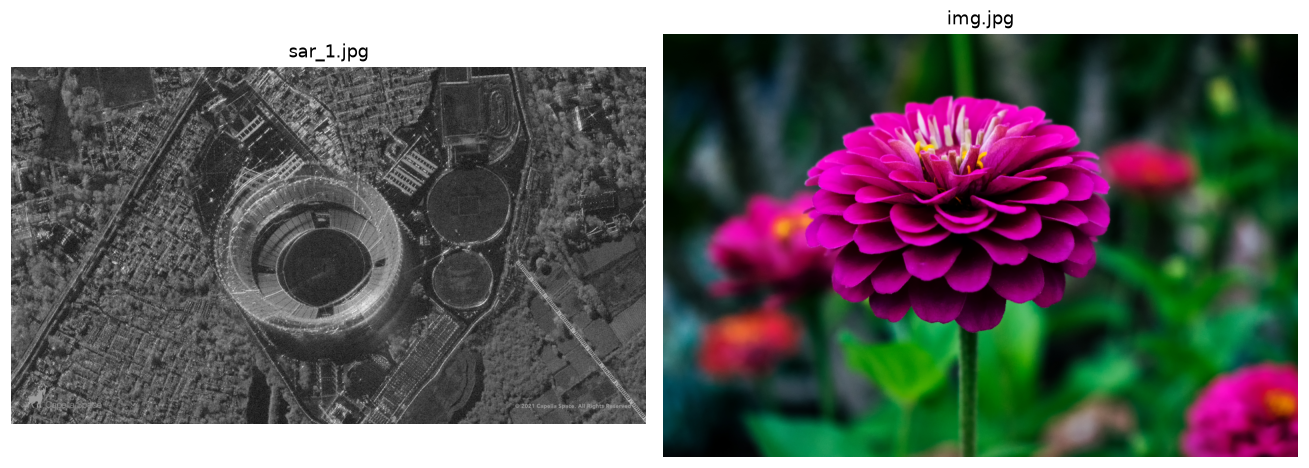

In [2]:
sar = cv2.imread(str(sar_path), cv2.IMREAD_GRAYSCALE)
flower_bgr = cv2.imread(str(flower_path), cv2.IMREAD_COLOR)
flower_rgb = cv2.cvtColor(flower_bgr, cv2.COLOR_BGR2RGB)

print('Размер sar_1.jpg:', sar.shape)
print('Размер img.jpg:', flower_rgb.shape)

fig, ax = plt.subplots(1, 2, figsize=(12, 5))
ax[0].imshow(sar, cmap='gray', vmin=0, vmax=255)
ax[0].set_title('sar_1.jpg')
ax[0].axis('off')
ax[1].imshow(flower_rgb)
ax[1].set_title('img.jpg')
ax[1].axis('off')
plt.tight_layout()

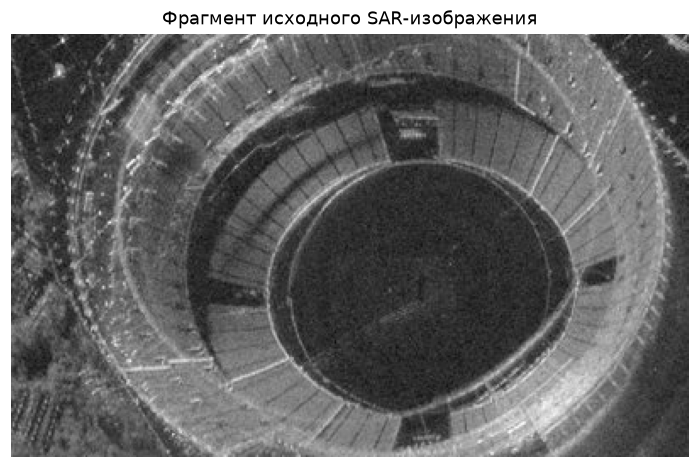

In [3]:
                                                               
roi = (slice(230, 480), slice(350, 750))

plt.figure(figsize=(8, 5))
plt.imshow(sar[roi], cmap='gray', vmin=0, vmax=255)
plt.title('Фрагмент исходного SAR-изображения')
plt.axis('off');

## 2. Добавление шума

Для гауссова шума взято стандартное отклонение 50. Отрицательные значения после генерации заменяются на ноль, поэтому добавляемый шум не уменьшает яркость пикселей.

Для постоянного шума берётся равномерное распределение от 0 до `b`. Значение `b` выбрано по формуле `b = std * sqrt(1.5)`.

In [4]:
std = 50
b = int(round(std * np.sqrt(1.5)))

def positive_gaussian(shape, std):
    noise = rng.normal(0, std, shape)
    return np.clip(noise, 0, 255).astype(np.uint8)

def uniform_noise(shape, border):
    return rng.integers(0, border + 1, size=shape, dtype=np.uint8)

noise_gauss = positive_gaussian(sar.shape, std)
noise_uniform = uniform_noise(sar.shape, b)

sar_gauss = cv2.add(sar, noise_gauss)
sar_uniform = cv2.add(sar, noise_uniform)

print(f'std = {std}, b = {b}')

std = 50, b = 61


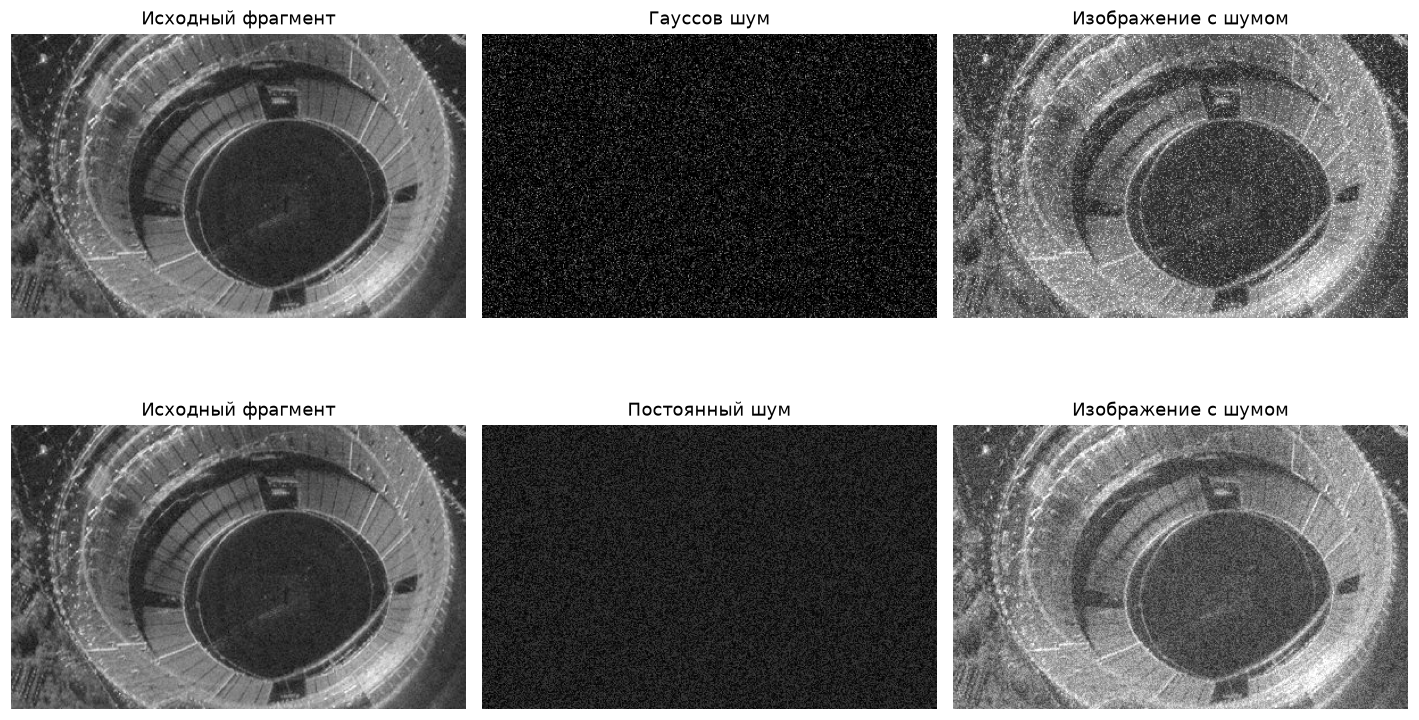

In [5]:
fig, ax = plt.subplots(2, 3, figsize=(13, 8))

items = [
    ('Гауссов шум', noise_gauss, sar_gauss),
    ('Постоянный шум', noise_uniform, sar_uniform),
]

for row, (name, noise, noisy) in enumerate(items):
    ax[row, 0].imshow(sar[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 0].set_title('Исходный фрагмент')
    ax[row, 1].imshow(noise[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 1].set_title(name)
    ax[row, 2].imshow(noisy[roi], cmap='gray', vmin=0, vmax=255)
    ax[row, 2].set_title('Изображение с шумом')

for a in ax.ravel():
    a.axis('off')
plt.tight_layout()

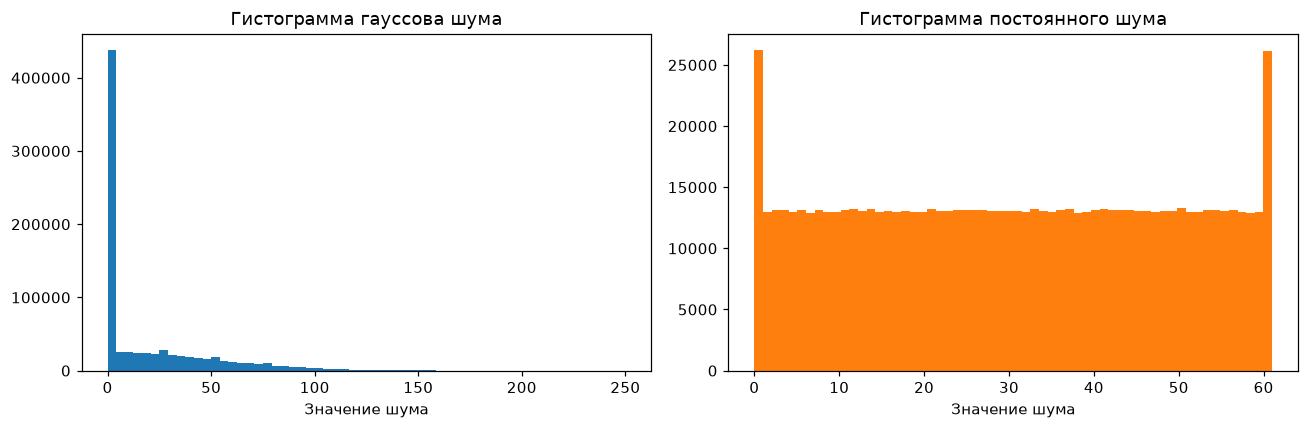

In [6]:
fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].hist(noise_gauss.ravel(), bins=60, color='tab:blue')
ax[0].set_title('Гистограмма гауссова шума')
ax[0].set_xlabel('Значение шума')
ax[1].hist(noise_uniform.ravel(), bins=60, color='tab:orange')
ax[1].set_title('Гистограмма постоянного шума')
ax[1].set_xlabel('Значение шума')
plt.tight_layout()

In [7]:
def metrics(reference, image):
    mse = mean_squared_error(reference, image)
    ssim = structural_similarity(reference, image, data_range=255)
    return mse, ssim

for name, image in [('Гауссов шум', sar_gauss), ('Постоянный шум', sar_uniform)]:
    mse, ssim = metrics(sar, image)
    print(f'{name:18} MSE = {mse:8.1f}, SSIM = {ssim:.3f}')

Гауссов шум        MSE =   1219.9, SSIM = 0.413
Постоянный шум     MSE =   1249.2, SSIM = 0.581


## 3. Проверка фильтров

Проверяются медианный, гауссовский, билатеральный фильтр и фильтр нелокальных средних (NLM). Для каждого фильтра взято несколько параметров.

In [8]:
def apply_filter(image, filter_name, params):
    if filter_name == 'median':
        return cv2.medianBlur(image, params[0])
    if filter_name == 'gaussian':
        k, sigma = params
        return cv2.GaussianBlur(image, (k, k), sigma)
    if filter_name == 'bilateral':
        return cv2.bilateralFilter(image, *params)
    if filter_name == 'nlm':
        return cv2.fastNlMeansDenoising(image, None, params[0], 7, 21)

variants = {
    'median': [(3,), (5,), (7,)],
    'gaussian': [(3, 0), (5, 0), (7, 1)],
    'bilateral': [(9, 50, 50), (9, 75, 75), (15, 75, 75)],
    'nlm': [(10,), (20,), (30,)],
}

noisy_images = [('gauss', sar_gauss), ('uniform', sar_uniform)]

In [9]:
                                                                              
results = []

for noise_name, noisy in noisy_images:
    mse, ssim = metrics(sar, noisy)
    results.append({
        'noise': noise_name, 'filter': 'без фильтра', 'params': '-',
        'mse': mse, 'ssim': ssim, 'image': noisy
    })

    for filter_name, params_list in variants.items():
        for params in params_list:
            filtered = apply_filter(noisy, filter_name, params)
            mse, ssim = metrics(sar, filtered)
            results.append({
                'noise': noise_name, 'filter': filter_name, 'params': str(params),
                'mse': mse, 'ssim': ssim, 'image': filtered
            })

print('Всего вариантов:', len(results))

Всего вариантов: 26


In [10]:
                                                           
for noise_name in ['gauss', 'uniform']:
    print('\nШум:', noise_name)
    print(f"{'Фильтр':14} {'Параметры':18} {'MSE':>10} {'SSIM':>8}")
    print('-' * 56)
    for row in results:
        if row['noise'] == noise_name:
            print(f"{row['filter']:14} {row['params']:18} {row['mse']:10.1f} {row['ssim']:8.3f}")


Шум: gauss
Фильтр         Параметры                 MSE     SSIM
--------------------------------------------------------
без фильтра    -                      1219.9    0.413
median         (3,)                    367.7    0.639
median         (5,)                    371.0    0.571
median         (7,)                    416.9    0.488
gaussian       (3, 0)                  569.0    0.667
gaussian       (5, 0)                  559.3    0.663
gaussian       (7, 1)                  556.8    0.668
bilateral      (9, 50, 50)             539.8    0.570
bilateral      (9, 75, 75)             524.6    0.583
bilateral      (15, 75, 75)            580.2    0.503
nlm            (10,)                  1219.8    0.413
nlm            (20,)                   685.1    0.577
nlm            (30,)                   589.9    0.510

Шум: uniform
Фильтр         Параметры                 MSE     SSIM
--------------------------------------------------------
без фильтра    -                      1249.2    0.

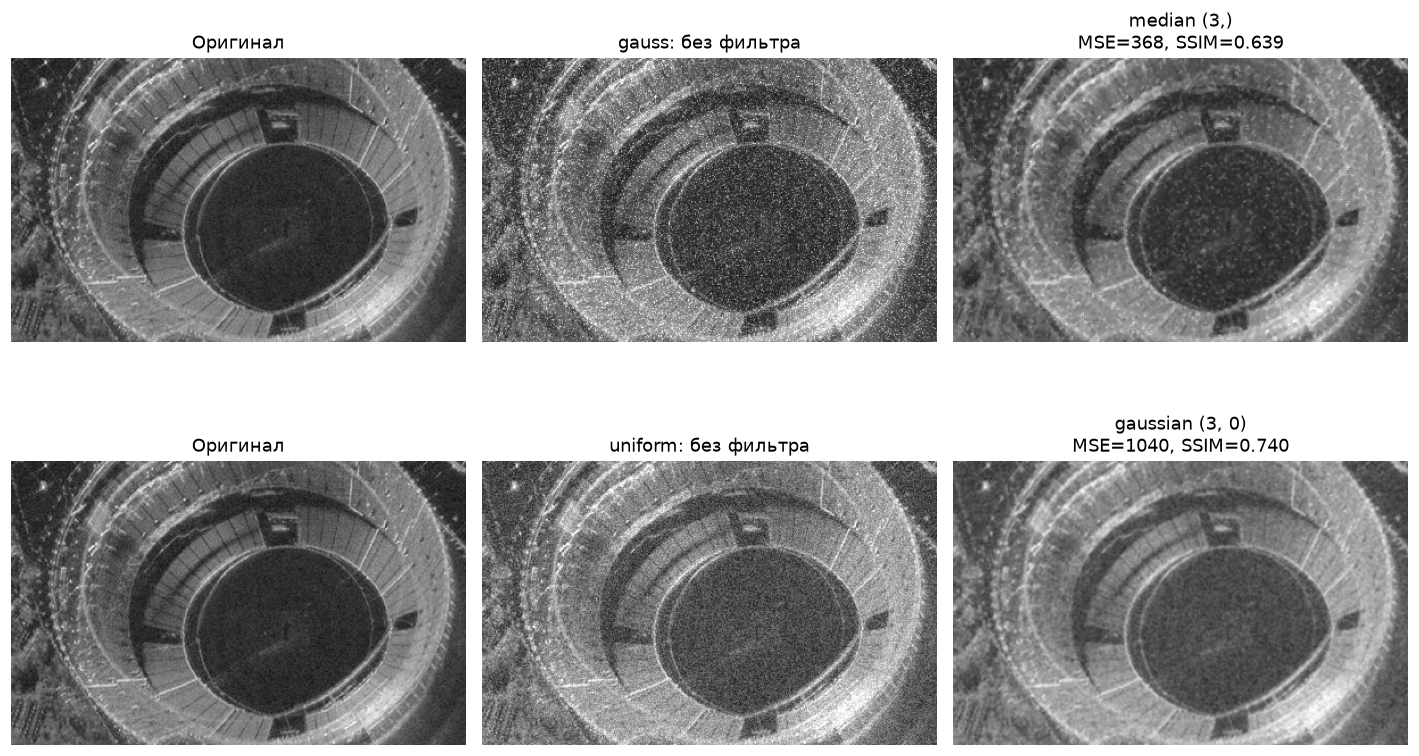

In [11]:
                                                             
def score(row, base):
    mse_part = (base['mse'] - row['mse']) / base['mse']
    ssim_part = row['ssim'] - base['ssim']
    return mse_part + ssim_part

best_by_score = {}
for noise_name in ['gauss', 'uniform']:
    rows = [r for r in results if r['noise'] == noise_name]
    base = next(r for r in rows if r['filter'] == 'без фильтра')
    filtered_rows = [r for r in rows if r['filter'] != 'без фильтра']
    best_by_score[noise_name] = max(filtered_rows, key=lambda r: score(r, base))

fig, ax = plt.subplots(2, 3, figsize=(13, 8))
for row_num, noise_name in enumerate(['gauss', 'uniform']):
    noisy = dict(noisy_images)[noise_name]
    best = best_by_score[noise_name]
    ax[row_num, 0].imshow(sar[roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 0].set_title('Оригинал')
    ax[row_num, 1].imshow(noisy[roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 1].set_title(f'{noise_name}: без фильтра')
    ax[row_num, 2].imshow(best['image'][roi], cmap='gray', vmin=0, vmax=255)
    ax[row_num, 2].set_title(f"{best['filter']} {best['params']}\nMSE={best['mse']:.0f}, SSIM={best['ssim']:.3f}")

for a in ax.ravel():
    a.axis('off')
plt.tight_layout()

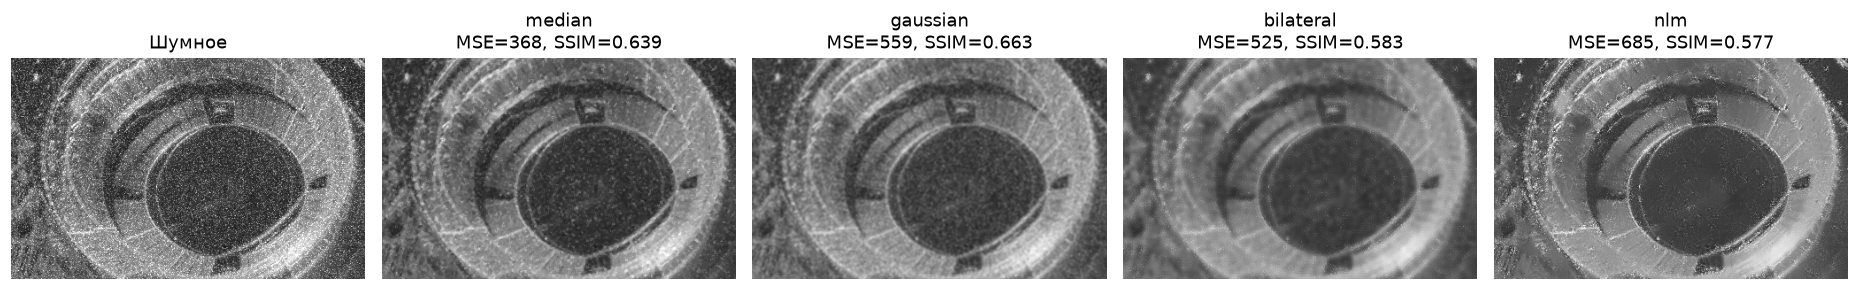

In [12]:
                                                                                   
test_variants = [
    ('median', (3,)),
    ('gaussian', (5, 0)),
    ('bilateral', (9, 75, 75)),
    ('nlm', (20,)),
]

fig, ax = plt.subplots(1, 5, figsize=(17, 4))
ax[0].imshow(sar_gauss[roi], cmap='gray', vmin=0, vmax=255)
ax[0].set_title('Шумное')

for i, (filter_name, params) in enumerate(test_variants, start=1):
    image = apply_filter(sar_gauss, filter_name, params)
    mse, ssim = metrics(sar, image)
    ax[i].imshow(image[roi], cmap='gray', vmin=0, vmax=255)
    ax[i].set_title(f'{filter_name}\nMSE={mse:.0f}, SSIM={ssim:.3f}')

for a in ax:
    a.axis('off')
plt.tight_layout()

## 4. Выводы

Лучшие варианты определяются отдельно по MSE (чем меньше, тем лучше) и по SSIM (чем ближе к 1, тем лучше). Визуальный результат также важен: слишком сильное сглаживание может улучшать одну метрику, но стирать мелкие детали.

In [13]:
for noise_name in ['gauss', 'uniform']:
    rows = [r for r in results if r['noise'] == noise_name and r['filter'] != 'без фильтра']
    best_mse = min(rows, key=lambda r: r['mse'])
    best_ssim = max(rows, key=lambda r: r['ssim'])
    best_common = best_by_score[noise_name]

    print(f'\nДля {noise_name} шума:')
    print(f"  Лучший MSE:  {best_mse['filter']} {best_mse['params']} -> {best_mse['mse']:.1f}")
    print(f"  Лучший SSIM: {best_ssim['filter']} {best_ssim['params']} -> {best_ssim['ssim']:.3f}")
    print(f"  Лучший общий вариант: {best_common['filter']} {best_common['params']}")


Для gauss шума:
  Лучший MSE:  median (3,) -> 367.7
  Лучший SSIM: gaussian (7, 1) -> 0.668
  Лучший общий вариант: median (3,)

Для uniform шума:
  Лучший MSE:  gaussian (3, 0) -> 1040.1
  Лучший SSIM: gaussian (3, 0) -> 0.740
  Лучший общий вариант: gaussian (3, 0)


## 5. Дополнительная проверка на цветном изображении

Для цветного изображения сначала уменьшим размер, чтобы обработка выполнялась быстрее. Здесь показан только один пример: положительный гауссов шум и медианный фильтр.

MSE / SSIM до фильтра: (np.float64(1229.045), np.float64(0.118))
MSE / SSIM после фильтра: (np.float64(211.559), np.float64(0.462))


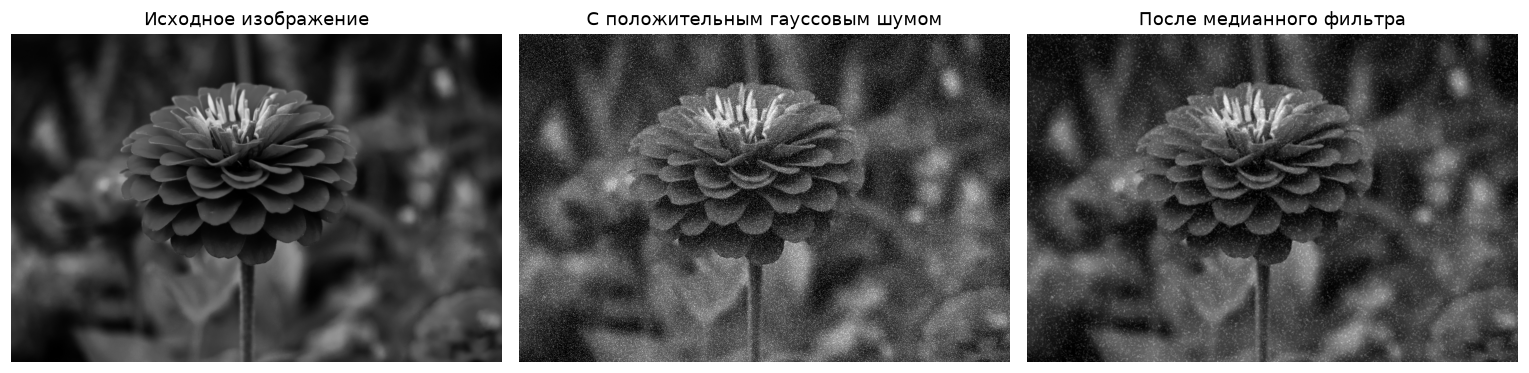

In [14]:
                                                              
scale = min(1.0, 1000 / max(flower_bgr.shape[:2]))
flower_small = cv2.resize(flower_bgr, None, fx=scale, fy=scale, interpolation=cv2.INTER_AREA)
flower_gray = cv2.cvtColor(flower_small, cv2.COLOR_BGR2GRAY)

flower_noise = positive_gaussian(flower_gray.shape, std)
flower_noisy = cv2.add(flower_gray, flower_noise)
flower_filtered = cv2.medianBlur(flower_noisy, 3)

fig, ax = plt.subplots(1, 3, figsize=(14, 5))
for a, image, title in zip(
    ax,
    [flower_gray, flower_noisy, flower_filtered],
    ['Исходное изображение', 'С положительным гауссовым шумом', 'После медианного фильтра']
):
    a.imshow(image, cmap='gray', vmin=0, vmax=255)
    a.set_title(title)
    a.axis('off')

plt.tight_layout()
print('MSE / SSIM до фильтра:', tuple(round(x, 3) for x in metrics(flower_gray, flower_noisy)))
print('MSE / SSIM после фильтра:', tuple(round(x, 3) for x in metrics(flower_gray, flower_filtered)))